In [1]:
import tensorflow as tf
import os
import matplotlib.pyplot as plt
import time

In [2]:
!rm /content/NH-HAZE.zip  # Remove corrupted file
!wget "https://data.vision.ee.ethz.ch/cvl/ntire20/nh-haze/files/NH-HAZE.zip" -O /content/NH-HAZE.zip

rm: cannot remove '/content/NH-HAZE.zip': No such file or directory
--2025-02-09 19:21:00--  https://data.vision.ee.ethz.ch/cvl/ntire20/nh-haze/files/NH-HAZE.zip
Resolving data.vision.ee.ethz.ch (data.vision.ee.ethz.ch)... 129.132.52.178, 2001:67c:10ec:36c2::178
Connecting to data.vision.ee.ethz.ch (data.vision.ee.ethz.ch)|129.132.52.178|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 330735056 (315M) [application/zip]
Saving to: ‘/content/NH-HAZE.zip’

/content/NH-HAZE.zi 100%[===================>] 315.41M  20.1MB/s    in 17s     

2025-02-09 19:21:18 (18.2 MB/s) - ‘/content/NH-HAZE.zip’ saved [330735056/330735056]



In [3]:
import zipfile
zip_ref = zipfile.ZipFile('/content/NH-HAZE.zip', 'r')
zip_ref.extractall('/content')
zip_ref.close()

In [4]:
import os
import shutil

def organize_nh_haze_dataset(source_folder, hazy_folder, gt_folder):

    # Create destination folders if they don't exist
    os.makedirs(hazy_folder, exist_ok=True)
    os.makedirs(gt_folder, exist_ok=True)

    # List all files in source folder
    files = os.listdir(source_folder)

    for file in files:
        source_path = os.path.join(source_folder, file)

        # Check if file is an image
        if file.lower().endswith(('.png', '.jpg', '.jpeg')):
            if "_hazy" in file:  # Move hazy images
                shutil.move(source_path, os.path.join(hazy_folder, file))
            else:  # Move ground truth images
                shutil.move(source_path, os.path.join(gt_folder, file))

    print("Dataset organized successfully!")

# Set paths (Change these as per your dataset location)
source_folder = "/content/NH-HAZE"
hazy_folder = "/content/hazy_images"
gt_folder = "/content/ground_truth"

# Run function
organize_nh_haze_dataset(source_folder, hazy_folder, gt_folder)


Dataset organized successfully!


In [5]:
import tensorflow as tf
import os
import cv2

def load_hazy_image(hazy_path, gt_path, img_size=(256, 256)):

    # Load images using OpenCV
    hazy_image = cv2.imread(hazy_path)
    gt_image = cv2.imread(gt_path)

    if hazy_image is None or gt_image is None:
        raise ValueError(f"Error loading image: {hazy_path} or {gt_path}")

    # Convert from BGR (OpenCV) to RGB
    hazy_image = cv2.cvtColor(hazy_image, cv2.COLOR_BGR2RGB)
    gt_image = cv2.cvtColor(gt_image, cv2.COLOR_BGR2RGB)

    # Resize images to desired size
    hazy_image = cv2.resize(hazy_image, img_size)
    gt_image = cv2.resize(gt_image, img_size)

    # Normalize pixel values to [0, 1]
    hazy_image = hazy_image.astype("float32") / 255.0
    gt_image = gt_image.astype("float32") / 255.0

    # Convert to TensorFlow tensors
    hazy_image = tf.convert_to_tensor(hazy_image, dtype=tf.float32)
    gt_image = tf.convert_to_tensor(gt_image, dtype=tf.float32)

    return hazy_image, gt_image


In [6]:
def load_hazy_dataset(hazy_folder, gt_folder, img_size=(256, 256)):

    hazy_images = sorted(os.listdir(hazy_folder))
    gt_images = sorted(os.listdir(gt_folder))

    dataset = []
    for hazy_img, gt_img in zip(hazy_images, gt_images):
        hazy_path = os.path.join(hazy_folder, hazy_img)
        gt_path = os.path.join(gt_folder, gt_img)

        hazy_tensor, gt_tensor = load_hazy_image(hazy_path, gt_path, img_size)
        dataset.append((hazy_tensor, gt_tensor))

    return dataset


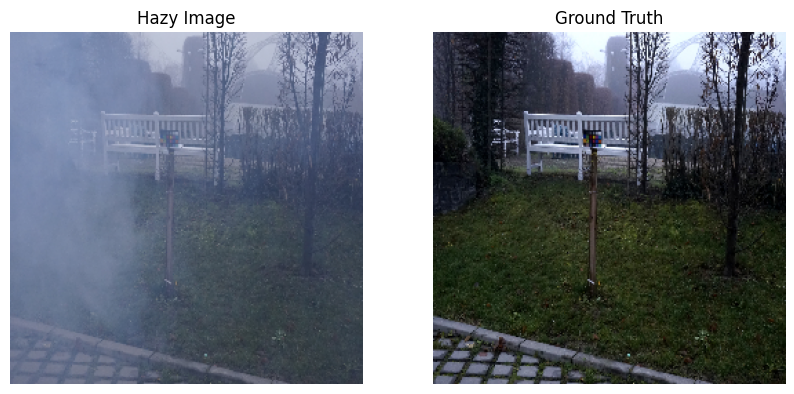

In [7]:
hazy_folder = "/content/hazy_images"
gt_folder = "/content/ground_truth"

dataset = load_hazy_dataset(hazy_folder, gt_folder)

# Example: Display first image pair
import matplotlib.pyplot as plt

hazy_img, gt_img = dataset[0]

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(hazy_img.numpy())
plt.title("Hazy Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gt_img.numpy())
plt.title("Ground Truth")
plt.axis("off")

plt.show()


In [8]:
IMG_WIDTH = 256
IMG_HEIGHT = 256
BUFFER_SIZE = 10
BATCH_SIZE = 1

In [9]:
def random_crop(hazy_image, gt_image):
  stacked_image = tf.stack([hazy_image, gt_image], axis=0)
  cropped_image = tf.image.random_crop(
      stacked_image, size=[2, IMG_HEIGHT, IMG_WIDTH, 3])

  return cropped_image[0], cropped_image[1]

In [10]:
def resize(hazy_image, gt_image, height, width):
  hazy_image = tf.image.resize(hazy_image, [height, width],
                                method=tf.image.ResizeMethod.NEAREST_NEIGHBOR)
  gt_image = tf.image.resize(gt_image, [height, width],
                               method=tf.image.ResizeMethod.NEAREST_NEIGHBOR)

  return hazy_image, gt_image

In [11]:
def normalize(hazy_image, gt_image):
  hazy_image = (hazy_image / 127.5) - 1
  gt_image = (gt_image / 127.5) - 1

  return hazy_image, gt_image

In [12]:
@tf.function()
def random_jitter(hazy_image, gt_image):
  # Resizing to 286x286
  input_image = hazy_image
  real_image = gt_image
  input_image, real_image = resize(input_image, real_image, 286, 286)

  # Random cropping back to 256x256
  input_image, real_image = random_crop(input_image, real_image)

  if tf.random.uniform(()) > 0.5:
    # Random mirroring
    hazy_image = tf.image.flip_left_right(input_image)
    gt_image = tf.image.flip_left_right(real_image)

  return hazy_image, gt_image

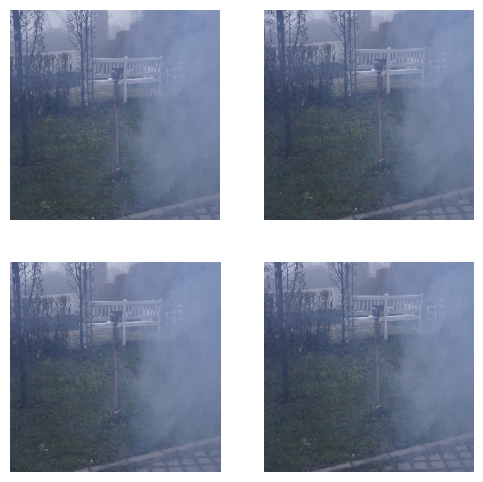

In [13]:
plt.figure(figsize=(6, 6))
for i in range(4):
  rj_inp, rj_re = random_jitter(hazy_img, gt_img)
  plt.subplot(2, 2, i + 1)
  plt.imshow(rj_inp)
  plt.axis('off')
plt.show()

In [14]:
import os
import shutil
import random

def split_dataset(hazy_folder, gt_folder, train_folder, test_folder, split_ratio=0.8):

    # Create train/test folders
    train_hazy = os.path.join(train_folder, "hazy")
    train_gt = os.path.join(train_folder, "ground_truth")
    test_hazy = os.path.join(test_folder, "hazy")
    test_gt = os.path.join(test_folder, "ground_truth")

    os.makedirs(train_hazy, exist_ok=True)
    os.makedirs(train_gt, exist_ok=True)
    os.makedirs(test_hazy, exist_ok=True)
    os.makedirs(test_gt, exist_ok=True)

    # Get list of hazy images (assuming naming consistency)
    all_hazy_images = sorted(os.listdir(hazy_folder))

    # Shuffle images randomly
    random.shuffle(all_hazy_images)

    # Split dataset into train and test
    split_idx = int(len(all_hazy_images) * split_ratio)
    train_images = all_hazy_images[:split_idx]
    test_images = all_hazy_images[split_idx:]

    for img in train_images:
        hazy_img_path = os.path.join(hazy_folder, img)
        gt_img_name = img.replace("_hazy", "_GT")  # Get the base name of the ground truth image
        gt_img_path = os.path.join(gt_folder, gt_img_name)

        if os.path.exists(hazy_img_path) and os.path.exists(gt_img_path):
            shutil.copy(hazy_img_path, os.path.join(train_hazy, img))  # Use shutil.copy instead of shutil.move
            shutil.copy(gt_img_path, os.path.join(train_gt, gt_img_name)) # Use shutil.copy instead of shutil.move
        else:
            print(f"Warning: Skipping image pair - hazy: {img}, ground truth: {gt_img_name} - one or both files not found.")



    all_gt_images = sorted(os.listdir(gt_folder))

    for img in test_images:
        hazy_img_path = os.path.join(hazy_folder, img)

        # Construct ground truth image name using the known format
        gt_img_name = img.replace("_hazy", "_GT")  # Replace "_hazy" with "_GT"
        gt_img_path = os.path.join(gt_folder, gt_img_name)

        # Check if both files exist before copying
        if os.path.exists(hazy_img_path) and os.path.exists(gt_img_path):
            shutil.copy(hazy_img_path, os.path.join(test_hazy, img))
            shutil.copy(gt_img_path, os.path.join(test_gt, gt_img_name))
        else:
            print(f"Warning: Skipping image pair - hazy: {img}, ground truth: {gt_img_name} - one or both files not found.")

    print("Dataset successfully split into Train and Test!")

hazy_folder = "/content/hazy_images"
gt_folder = "/content/ground_truth"
train_folder = "/content/train"
test_folder = "/content/test"

# Split the dataset
split_dataset(hazy_folder, gt_folder, train_folder, test_folder, split_ratio=0.8)

Dataset successfully split into Train and Test!


In [15]:
OUTPUT_CHANNELS = 3

In [16]:
def downsample(filters, size, apply_batchnorm=True):
  initializer = tf.random_normal_initializer(0., 0.02)

  result = tf.keras.Sequential()
  result.add(
      tf.keras.layers.Conv2D(filters, size, strides=2, padding='same',
                             kernel_initializer=initializer, use_bias=False))

  if apply_batchnorm:
    result.add(tf.keras.layers.BatchNormalization())

  result.add(tf.keras.layers.LeakyReLU())

  return result

In [17]:
down_model = downsample(3, 4)
# Assuming 'hazy_img' from your previous cells contains the image data
down_result = down_model(tf.expand_dims(hazy_img, 0))
print (down_result.shape)

(1, 128, 128, 3)


In [18]:
def upsample(filters, size, apply_dropout=False):
  initializer = tf.random_normal_initializer(0., 0.02)

  result = tf.keras.Sequential()
  result.add(
    tf.keras.layers.Conv2DTranspose(filters, size, strides=2,
                                    padding='same',
                                    kernel_initializer=initializer,
                                    use_bias=False))

  result.add(tf.keras.layers.BatchNormalization())

  if apply_dropout:
      result.add(tf.keras.layers.Dropout(0.5))

  result.add(tf.keras.layers.ReLU())

  return result

In [19]:
up_model = upsample(3, 4)
up_result = up_model(down_result)
print (up_result.shape)

(1, 256, 256, 3)


In [20]:
def Generator():
  inputs = tf.keras.layers.Input(shape=[256, 256, 3])

  down_stack = [
    downsample(64, 4, apply_batchnorm=False),  # (batch_size, 128, 128, 64)
    downsample(128, 4),  # (batch_size, 64, 64, 128)
    downsample(256, 4),  # (batch_size, 32, 32, 256)
    downsample(512, 4),  # (batch_size, 16, 16, 512)
    downsample(512, 4),  # (batch_size, 8, 8, 512)
    downsample(512, 4),  # (batch_size, 4, 4, 512)
    downsample(512, 4),  # (batch_size, 2, 2, 512)
    downsample(512, 4),  # (batch_size, 1, 1, 512)
  ]

  up_stack = [
    upsample(512, 4, apply_dropout=True),  # (batch_size, 2, 2, 1024)
    upsample(512, 4, apply_dropout=True),  # (batch_size, 4, 4, 1024)
    upsample(512, 4, apply_dropout=True),  # (batch_size, 8, 8, 1024)
    upsample(512, 4),  # (batch_size, 16, 16, 1024)
    upsample(256, 4),  # (batch_size, 32, 32, 512)
    upsample(128, 4),  # (batch_size, 64, 64, 256)
    upsample(64, 4),  # (batch_size, 128, 128, 128)
  ]

  initializer = tf.random_normal_initializer(0., 0.02)
  last = tf.keras.layers.Conv2DTranspose(OUTPUT_CHANNELS, 4,
                                         strides=2,
                                         padding='same',
                                         kernel_initializer=initializer,
                                         activation='tanh')  # (batch_size, 256, 256, 3)

  x = inputs

  # Downsampling through the model
  skips = []
  for down in down_stack:
    x = down(x)
    skips.append(x)

  skips = reversed(skips[:-1])

  # Upsampling and establishing the skip connections
  for up, skip in zip(up_stack, skips):
    x = up(x)
    x = tf.keras.layers.Concatenate()([x, skip])

  x = last(x)

  return tf.keras.Model(inputs=inputs, outputs=x)

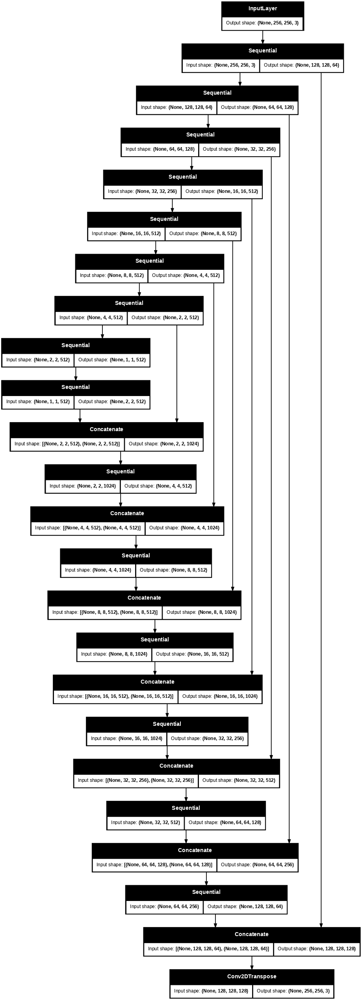

In [21]:
generator = Generator()
tf.keras.utils.plot_model(generator, show_shapes=True, dpi=64)

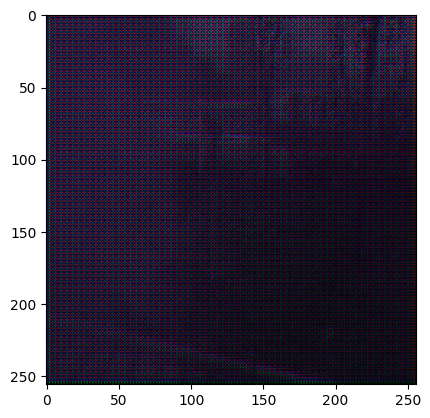

In [22]:
gen_output = generator(hazy_img[tf.newaxis, ...], training=False)
gen_output = gen_output / tf.reduce_max(gen_output) # Use tf.reduce_max to get the maximum value
plt.imshow(gen_output[0, ...])

In [23]:
LAMBDA = 100

In [24]:
loss_object = tf.keras.losses.BinaryCrossentropy(from_logits=True)

In [25]:
def generator_loss(disc_generated_output, gen_output, target):
  gan_loss = loss_object(tf.ones_like(disc_generated_output), disc_generated_output)

  # Mean absolute error
  l1_loss = tf.reduce_mean(tf.abs(target - gen_output))

  total_gen_loss = gan_loss + (LAMBDA * l1_loss)

  return total_gen_loss, gan_loss, l1_loss

In [26]:
def Discriminator():
  initializer = tf.random_normal_initializer(0., 0.02)

  inp = tf.keras.layers.Input(shape=[256, 256, 3], name='input_image')
  tar = tf.keras.layers.Input(shape=[256, 256, 3], name='target_image')

  x = tf.keras.layers.concatenate([inp, tar])  # (batch_size, 256, 256, channels*2)

  down1 = downsample(64, 4, False)(x)  # (batch_size, 128, 128, 64)
  down2 = downsample(128, 4)(down1)  # (batch_size, 64, 64, 128)
  down3 = downsample(256, 4)(down2)  # (batch_size, 32, 32, 256)

  zero_pad1 = tf.keras.layers.ZeroPadding2D()(down3)  # (batch_size, 34, 34, 256)
  conv = tf.keras.layers.Conv2D(512, 4, strides=1,
                                kernel_initializer=initializer,
                                use_bias=False)(zero_pad1)  # (batch_size, 31, 31, 512)

  batchnorm1 = tf.keras.layers.BatchNormalization()(conv)

  leaky_relu = tf.keras.layers.LeakyReLU()(batchnorm1)

  zero_pad2 = tf.keras.layers.ZeroPadding2D()(leaky_relu)  # (batch_size, 33, 33, 512)

  last = tf.keras.layers.Conv2D(1, 4, strides=1,
                                kernel_initializer=initializer)(zero_pad2)  # (batch_size, 30, 30, 1)

  return tf.keras.Model(inputs=[inp, tar], outputs=last)

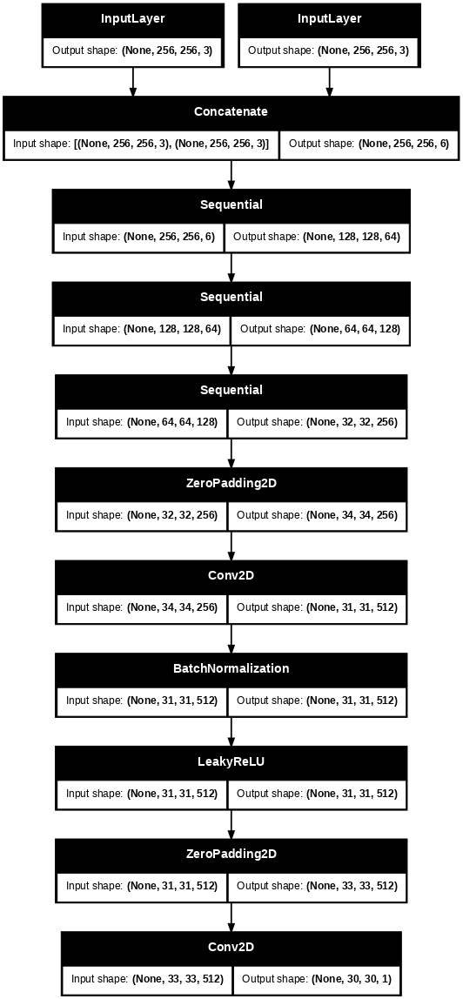

In [27]:
discriminator = Discriminator()
tf.keras.utils.plot_model(discriminator, show_shapes=True, dpi=64)

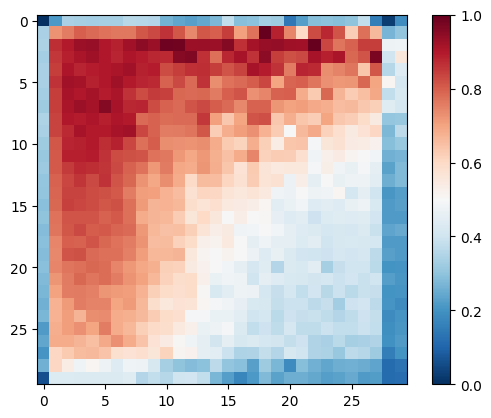

In [28]:
import numpy as np

disc_out = discriminator([hazy_img[tf.newaxis, ...], gen_output], training=False)
disc_out_normalized = (disc_out[0, ..., -1] - np.min(disc_out[0, ..., -1])) / (np.max(disc_out[0, ..., -1]) - np.min(disc_out[0, ..., -1]))
plt.imshow(disc_out_normalized, cmap='RdBu_r')  # No need for vmin/vmax here
plt.colorbar()

In [29]:
def discriminator_loss(disc_real_output, disc_generated_output):
  real_loss = loss_object(tf.ones_like(disc_real_output), disc_real_output)

  generated_loss = loss_object(tf.zeros_like(disc_generated_output), disc_generated_output)

  total_disc_loss = real_loss + generated_loss

  return total_disc_loss

In [30]:
generator_optimizer = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)
discriminator_optimizer = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)

In [31]:
checkpoint_dir = './training_checkpoints'
checkpoint_prefix = os.path.join(checkpoint_dir, "ckpt")
checkpoint = tf.train.Checkpoint(generator_optimizer=generator_optimizer,
                                 discriminator_optimizer=discriminator_optimizer,
                                 generator=generator,
                                 discriminator=discriminator)

In [32]:
def generate_images(model, test_input, tar):
  prediction = model(test_input, training=True)
  plt.figure(figsize=(15, 15))

  display_list = [test_input[0], tar[0], prediction[0]]
  title = ['Input Image', 'Ground Truth', 'Predicted Image']

  for i in range(3):
    plt.subplot(1, 3, i+1)
    plt.title(title[i])
    # Getting the pixel values in the [0, 1] range to plot.
    # Use tf.reduce_min and tf.reduce_max for TensorFlow tensors
    plt.imshow((display_list[i] - tf.reduce_min(display_list[i])) / (tf.reduce_max(display_list[i]) - tf.reduce_min(display_list[i])))  # Rescale the data
    plt.axis('off')
  plt.show()

In [33]:
example_input_path = '/content/test/hazy/05_hazy.png' # Changed this to hazy image path
example_target_path = '/content/test/ground_truth/05_GT.png'

# Load and preprocess the images
example_input, _ = load_hazy_image(example_input_path, example_target_path) # load_hazy_image expects hazy path first
# Apply random jitter if needed:
# example_input, _ = random_jitter(example_input, example_input)
example_input, _ = normalize(example_input, example_input)

_,example_target = load_hazy_image(example_input_path, example_target_path) # load_hazy_image expects hazy path first
# Apply random jitter if needed:
# example_target, _ = random_jitter(example_target, example_target)
example_target, _ = normalize(example_target, example_target)


generate_images(generator, example_input[tf.newaxis,...], example_target[tf.newaxis,...]) # Add batch dimension

ValueError: Error loading image: /content/test/hazy/05_hazy.png or /content/test/ground_truth/05_GT.png

In [34]:
example_input_path = '/content/test/ground_truth/05_GT.png'
example_target_path = '/content/test/hazy/05_hazy.png'

# Load and preprocess the images
example_input, _ = load_hazy_image(example_target_path, example_input_path) # load_hazy_image expects hazy path first
# Apply random jitter if needed:
# example_input, _ = random_jitter(example_input, example_input)
example_input, _ = normalize(example_input, example_input)

_,example_target = load_hazy_image(example_target_path, example_input_path) # load_hazy_image expects hazy path first
# Apply random jitter if needed:
# example_target, _ = random_jitter(example_target, example_target)
example_target, _ = normalize(example_target, example_target)


generate_images(generator, example_input[tf.newaxis,...], example_target[tf.newaxis,...]) # Add batch dimension

ValueError: Error loading image: /content/test/hazy/05_hazy.png or /content/test/ground_truth/05_GT.png

In [35]:
import datetime
log_dir="logs/"

summary_writer = tf.summary.create_file_writer(
  log_dir + "fit/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S"))

In [36]:
@tf.function
def train_step(input_image, target, step):
  with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
    gen_output = generator(input_image, training=True)

    disc_real_output = discriminator([input_image, target], training=True)
    disc_generated_output = discriminator([input_image, gen_output], training=True)

    gen_total_loss, gen_gan_loss, gen_l1_loss = generator_loss(disc_generated_output, gen_output, target)
    disc_loss = discriminator_loss(disc_real_output, disc_generated_output)

  generator_gradients = gen_tape.gradient(gen_total_loss,
                                          generator.trainable_variables)
  discriminator_gradients = disc_tape.gradient(disc_loss,
                                               discriminator.trainable_variables)

  generator_optimizer.apply_gradients(zip(generator_gradients,
                                          generator.trainable_variables))
  discriminator_optimizer.apply_gradients(zip(discriminator_gradients,
                                              discriminator.trainable_variables))

  with summary_writer.as_default():
    tf.summary.scalar('gen_total_loss', gen_total_loss, step=step//1000)
    tf.summary.scalar('gen_gan_loss', gen_gan_loss, step=step//1000)
    tf.summary.scalar('gen_l1_loss', gen_l1_loss, step=step//1000)
    tf.summary.scalar('disc_loss', disc_loss, step=step//1000)

In [37]:
from IPython import display
def fit(train_ds, test_ds, steps):
  example_input, example_target = next(iter(test_ds.take(1)))
  start = time.time()

  for step, (input_image, target) in train_ds.repeat().take(steps).enumerate():
    if (step) % 1000 == 0:
      display.clear_output(wait=True)

      if step != 0:
        print(f'Time taken for 1000 steps: {time.time()-start:.2f} sec\n')

      start = time.time()

      generate_images(generator, example_input, example_target)
      print(f"Step: {step//1000}k")

    train_step(input_image, target, step)

    # Training step
    if (step+1) % 10 == 0:
      print('.', end='', flush=True)


    # Save (checkpoint) the model every 5k steps
    if (step + 1) % 5000 == 0:
      checkpoint.save(file_prefix=checkpoint_prefix)

In [38]:
%load_ext tensorboard
%tensorboard --logdir {log_dir}

<IPython.core.display.Javascript object>

In [39]:
import tensorflow as tf
import os
import numpy as np

IMG_SIZE = 256  # Standard size for Pix2Pix

def load_image_train(hazy_path, gt_path):

    # Read images
    hazy_image = tf.io.read_file(hazy_path)
    gt_image = tf.io.read_file(gt_path)

    # Decode images
    hazy_image = tf.image.decode_jpeg(hazy_image, channels=3)
    gt_image = tf.image.decode_jpeg(gt_image, channels=3)

    # Convert to float32
    hazy_image = tf.image.convert_image_dtype(hazy_image, tf.float32)
    gt_image = tf.image.convert_image_dtype(gt_image, tf.float32)

    # Resize to (256, 256)
    hazy_image = tf.image.resize(hazy_image, [IMG_SIZE, IMG_SIZE])
    gt_image = tf.image.resize(gt_image, [IMG_SIZE, IMG_SIZE])

    # Normalize to [-1, 1]
    hazy_image = (hazy_image * 2.0) - 1.0
    gt_image = (gt_image * 2.0) - 1.0

    return hazy_image, gt_image

def load_train_dataset(train_hazy_folder, train_gt_folder, batch_size=8):

    # List all images in train hazy folder
    hazy_images = sorted(os.listdir(train_hazy_folder))

    # Generate full paths for hazy & ground truth images
    hazy_paths = [os.path.join(train_hazy_folder, img) for img in hazy_images]
    # Correctly generate ground truth image paths by replacing "_hazy" with "_GT"
    gt_paths = [os.path.join(train_gt_folder, img.replace("_hazy", "_GT")) for img in hazy_images]

    # Create a dataset
    dataset = tf.data.Dataset.from_tensor_slices((hazy_paths, gt_paths))

    # Load images
    dataset = dataset.map(load_image_train, num_parallel_calls=tf.data.AUTOTUNE)

    # Shuffle, batch, and prefetch for performance
    dataset = dataset.shuffle(100).batch(batch_size).prefetch(tf.data.AUTOTUNE)

    return dataset

# ... (rest of your code)

# Set folder paths (Modify as per your dataset)
train_hazy_folder = "/content/train/hazy"
train_gt_folder = "/content/train/ground_truth"

# Load dataset
train_dataset = load_train_dataset(train_hazy_folder, train_gt_folder)


In [40]:
import tensorflow as tf
import os

IMG_SIZE = 256  # Standard size for Pix2Pix

def load_image_test(hazy_path, gt_path):
    # Read images
    hazy_image = tf.io.read_file(hazy_path)
    gt_image = tf.io.read_file(gt_path)

    # Decode images
    hazy_image = tf.image.decode_jpeg(hazy_image, channels=3)
    gt_image = tf.image.decode_jpeg(gt_image, channels=3)

    # Convert to float32
    hazy_image = tf.image.convert_image_dtype(hazy_image, tf.float32)
    gt_image = tf.image.convert_image_dtype(gt_image, tf.float32)

    # Resize to (256, 256)
    hazy_image = tf.image.resize(hazy_image, [IMG_SIZE, IMG_SIZE])
    gt_image = tf.image.resize(gt_image, [IMG_SIZE, IMG_SIZE])

    # Normalize to [-1, 1]
    hazy_image = (hazy_image * 2.0) - 1.0
    gt_image = (gt_image * 2.0) - 1.0

    return hazy_image, gt_image

def load_test_dataset(test_hazy_folder, test_gt_folder, batch_size=8):

    # List all images in test hazy folder
    hazy_images = sorted(os.listdir(test_hazy_folder))

    # Generate full paths for hazy & ground truth images
    hazy_paths = [os.path.join(test_hazy_folder, img) for img in hazy_images]

    # Corrected line: Replace '_hazy' with '_GT' to match ground truth filenames
    # Adding error handling if a corresponding ground truth file is not found
    gt_paths = []
    for img in hazy_images:
        gt_img_name = img.replace("_hazy", "_GT")
        gt_path = os.path.join(test_gt_folder, gt_img_name)
        if os.path.exists(gt_path):
            gt_paths.append(gt_path)
        else:
            print(f"Warning: Ground truth image not found for {img}. Skipping this pair.")

    # Create a dataset using only the pairs where ground truth exists
    dataset = tf.data.Dataset.from_tensor_slices((hazy_paths[:len(gt_paths)], gt_paths))

    # Load images
    dataset = dataset.map(load_image_test, num_parallel_calls=tf.data.AUTOTUNE)

    # Batch and prefetch for performance (no shuffling for test data)
    dataset = dataset.batch(batch_size).prefetch(tf.data.AUTOTUNE)

    return dataset

# Set folder paths (Modify as per your dataset)
test_hazy_folder = "/content/test/hazy"
test_gt_folder = "/content/test/ground_truth"

# Load dataset
test_dataset = load_test_dataset(test_hazy_folder, test_gt_folder)




Time taken for 1000 steps: 855.75 sec



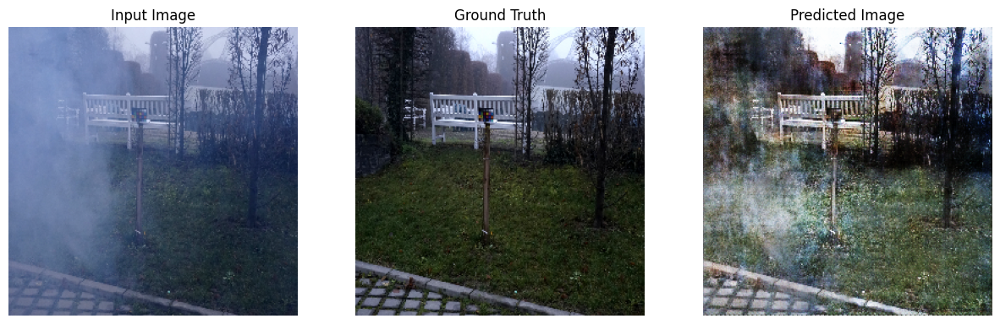

Step: 1k
....................................................................................................

In [41]:
import time
fit(train_dataset, test_dataset, steps=2000)

In [43]:
# Save the trained Pix2Pix model
def save_model(model, save_path):
    # Add the .keras extension to the save_path
    save_path = save_path + ".keras"  # or save_path + ".h5"
    model.save(save_path)
    print(f"Model saved successfully at {save_path}")

# Example usage after training
model_save_path = "/content/pix2pix"  # Change this to your desired path
save_model(generator, model_save_path)  # Save only the generator



Model saved successfully at /content/pix2pix.keras


In [45]:
# Load the trained model for inference
from tensorflow.keras.models import load_model

# Add the .keras extension to the model_save_path when loading
loaded_model = load_model(model_save_path + ".keras")
print("Model loaded successfully!")

Model loaded successfully!


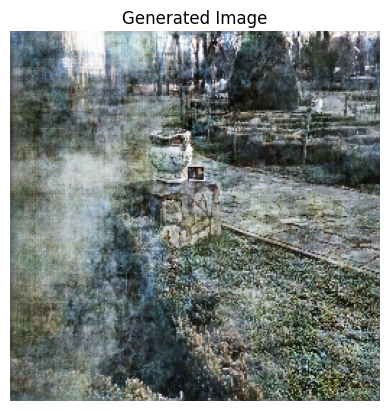

In [46]:
import tensorflow as tf
import matplotlib.pyplot as plt
import cv2

def load_and_preprocess_image(image_path):
    """Loads an image from the given path, preprocesses it, and returns a TensorFlow tensor."""

    # 1. Load image using OpenCV
    img = cv2.imread(image_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # Convert to RGB

    # 2. Resize
    img = cv2.resize(img, (256, 256))

    # 3. Convert to float32 and normalize to [-1, 1]
    img = img.astype(np.float32) / 127.5 - 1

    # 4. Convert to TensorFlow tensor and add batch dimension
    img_tensor = tf.expand_dims(img, axis=0)

    return img_tensor

def generate_and_display_image(model, image_path):
    """Generates an image using the model and displays it."""

    # 1. Load and preprocess the input image
    input_image = load_and_preprocess_image(image_path)

    # 2. Generate the output image
    generated_image = model(input_image, training=False)

    # 3. Rescale the generated image to [0, 1] for display
    generated_image = (generated_image + 1) / 2.0

    # 4. Display the generated image
    plt.imshow(generated_image[0])  # Remove batch dimension for display
    plt.axis('off')
    plt.title("Generated Image")
    plt.show()

# Example usage:
image_path = "/content/hazy_images/03_hazy.png"  # Replace with your image path
generate_and_display_image(loaded_model, image_path)

In [47]:
import tensorflow as tf
import matplotlib.pyplot as plt
import cv2
import os
import numpy as np

# ... (load_and_preprocess_image function from previous response) ...

def generate_and_save_images(model, hazy_images_folder, output_folder):
    """Generates images for all hazy images in the input folder and saves them to the output folder."""

    # Create the output folder if it doesn't exist
    os.makedirs(output_folder, exist_ok=True)

    # Get a list of all hazy image files
    hazy_image_files = [f for f in os.listdir(hazy_images_folder) if os.path.isfile(os.path.join(hazy_images_folder, f))]

    for hazy_image_file in hazy_image_files:
        # Construct the full path to the hazy image
        hazy_image_path = os.path.join(hazy_images_folder, hazy_image_file)

        # Load and preprocess the hazy image
        input_image = load_and_preprocess_image(hazy_image_path)

        # Generate the dehazed image
        generated_image = model(input_image, training=False)

        # Rescale the generated image to [0, 255] and convert to uint8
        generated_image = (generated_image + 1) / 2.0 * 255.0
        generated_image = tf.cast(generated_image, tf.uint8)

        # Convert the TensorFlow tensor to a NumPy array for saving
        generated_image_np = generated_image[0].numpy()  # Remove batch dimension

        # Construct the output file path
        output_file_path = os.path.join(output_folder, hazy_image_file)  # Use the same filename as the hazy image

        # Save the generated image
        cv2.imwrite(output_file_path, cv2.cvtColor(generated_image_np, cv2.COLOR_RGB2BGR))  # Convert back to BGR for saving

        print(f"Generated and saved image: {output_file_path}")


# Example usage:
hazy_images_folder = "/content/hazy_images"  # Path to your hazy images folder
output_folder = "/content/generated_images"  # Path to the folder where generated images will be saved

generate_and_save_images(loaded_model, hazy_images_folder, output_folder)

Generated and saved image: /content/generated_images/16_hazy.png
Generated and saved image: /content/generated_images/11_hazy.png
Generated and saved image: /content/generated_images/08_hazy.png
Generated and saved image: /content/generated_images/51_hazy.png
Generated and saved image: /content/generated_images/13_hazy.png
Generated and saved image: /content/generated_images/14_hazy.png
Generated and saved image: /content/generated_images/30_hazy.png
Generated and saved image: /content/generated_images/50_hazy.png
Generated and saved image: /content/generated_images/32_hazy.png
Generated and saved image: /content/generated_images/27_hazy.png
Generated and saved image: /content/generated_images/23_hazy.png
Generated and saved image: /content/generated_images/52_hazy.png
Generated and saved image: /content/generated_images/34_hazy.png
Generated and saved image: /content/generated_images/21_hazy.png
Generated and saved image: /content/generated_images/05_hazy.png
Generated and saved image

In [48]:
!pip install image-similarity-measures

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.9/12.9 MB 101.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 109.1 MB/s eta 0:00:00
  Created wheel for phasepack: filename=phasepack-1.5-py3-none-any.whl size=26961 sha256=f3921d069df1735d39cca11bc67d01602fb0af3afaa612233cde2d64a0ef05f0
  Stored in directory: /root/.cache/pip/wheels/4e/35/07/5dc3bc29c9479ec3050dcda98b2c905f059e8b122299034223
Successfully built phasepack
  Attempting uninstall: scikit-image
    Found existing installation: scikit-image 0.25.1
    Uninstalling scikit-image-0.25.1:
      Successfully uninstalled scikit-image-0.25.1


In [ ]:
import cv2
import numpy as np
import os
import pandas as pd
from image_similarity_measures.quality_metrics import rmse, ssim, fsim, issm

def calculate_similarity_measures(generated_images_folder, ground_truth_folder):
    results = []
    generated_image_files = [f for f in os.listdir(generated_images_folder) if os.path.isfile(os.path.join(generated_images_folder, f))]

    for image_file in generated_image_files:
        generated_image_path = os.path.join(generated_images_folder, image_file)
        ground_truth_image_file = image_file.replace("_hazy", "_GT")
        ground_truth_image_path = os.path.join(ground_truth_folder, ground_truth_image_file)

        generated_image = cv2.imread(generated_image_path)
        ground_truth_image = cv2.imread(ground_truth_image_path)

        if generated_image is None:
            print(f"Warning: Could not load generated image: {generated_image_path}. Skipping this image.")
            continue
        if ground_truth_image is None:
            print(f"Warning: Could not load ground truth image: {ground_truth_image_path}. Skipping this image.")
            continue

        ground_truth_image = cv2.resize(ground_truth_image, (generated_image.shape[1], generated_image.shape[0]))

        rmse_value = rmse(generated_image, ground_truth_image)
        ssim_value = ssim(generated_image, ground_truth_image)
        fsim_value = fsim(generated_image, ground_truth_image)
        issm_value = issm(generated_image, ground_truth_image)

        results.append({
            "image_file": image_file,
            "rmse": rmse_value,
            "ssim": ssim_value,
            "fsim": fsim_value,
            "issm": issm_value
        })

    return results

generated_images_folder = "/content/generated_images"
ground_truth_folder = "/content/ground_truth"

similarity_results = calculate_similarity_measures(generated_images_folder, ground_truth_folder)

for result in similarity_results:
    print(f"Image: {result['image_file']}, RMSE: {result['rmse']}, SSIM: {result['ssim']}, FSIM: {result['fsim']}, ISSM: {result['issm']}")

df = pd.DataFrame(similarity_results)
excel_file_path = "/content/similarity_results.xlsx"
df.to_excel(excel_file_path, index=False)

print(f"Similarity results saved to: {excel_file_path}")


/usr/local/lib/python3.11/dist-packages/image_similarity_measures/quality_metrics.py:171: RuntimeWarning: divide by zero encountered in log2
  return -np.sum(np.nan_to_num(H * np.log2(H)))
/usr/local/lib/python3.11/dist-packages/image_similarity_measures/quality_metrics.py:171: RuntimeWarning: invalid value encountered in multiply
  return -np.sum(np.nan_to_num(H * np.log2(H)))
/usr/local/lib/python3.11/dist-packages/image_similarity_measures/quality_metrics.py:188: RuntimeWarning: invalid value encountered in scalar divide
  return numerator / denominator


Image: 16_hazy.png, RMSE: 0.0030735693871974945, SSIM: 0.9891259738059216, FSIM: 0.7514922426164629, ISSM: 0.0
Image: 11_hazy.png, RMSE: 0.0031647589057683945, SSIM: 0.9890661785549497, FSIM: 0.7622063464221404, ISSM: 0.0
Image: 08_hazy.png, RMSE: 0.002913201227784157, SSIM: 0.9918844863738775, FSIM: 0.7433233783640113, ISSM: 0.0
Image: 51_hazy.png, RMSE: 0.0029098864179104567, SSIM: 0.9911754530713687, FSIM: 0.7446208533693764, ISSM: 0.0
Image: 13_hazy.png, RMSE: 0.0029400065541267395, SSIM: 0.991138103974914, FSIM: 0.772517326059699, ISSM: 0.0
Image: 14_hazy.png, RMSE: 0.002653764560818672, SSIM: 0.9934814440585521, FSIM: 0.753070325949341, ISSM: 0.0
Image: 30_hazy.png, RMSE: 0.010351534001529217, SSIM: 0.90805263413321, FSIM: 0.6268300569507069, ISSM: 0.0
Image: 50_hazy.png, RMSE: 0.003808763576671481, SSIM: 0.9854106981045595, FSIM: 0.7723765909479884, ISSM: 0.0
Image: 32_hazy.png, RMSE: 0.002756276400759816, SSIM: 0.9924843780813507, FSIM: 0.7849213387432638, ISSM: 0.0
Image: 27_h